# Online cursor control via motoneuron decorrelation

This notebook implements a **PD controller that decorrelates a pair of motoneurons** driven by a *common* excitatory input, reproducing the transient flexible-control experiments of Bräcklein et al. (2022). By applying a *differential* inhibition to one unit and iteratively reshaping the common drive, the controller steers the pair's 2D firing-rate "cursor" along a target path, first decorrelating the two units, then selectively raising one of them.

**Model.** Each motoneuron is the two-compartment biophysical model with a dendritic persistent inward current (PIC). The active per-step equations are the *controller* variant (`sim_ode_online_control_exp.jl`), where the per-unit inhibition factor `IF` is gated on PIC state.

---

## 1. Environment setup

### 1.1 Package imports

In [1]:
# Core packages
using Distributions, Random
using Parameters, Match, SymDict

# Data handling
using JLD, JLD2, MAT, CSV, DataFrames, XLSX, Serialization

# Numerical methods
using DSP, NumericalIntegration, GLM
using Optim, JuMP, Ipopt

# Visualization
using Plots, CairoMakie, Makie, PyPlot
using Colors, ColorSchemes

# Logging and tracking
using Wandb, PyCall, Logging

# Package management
using Pkg
Pkg.resolve()

println("✓ All packages loaded successfully")

┌ Warning: Package Polynomials does not have MakieCore in its dependencies:
│ - If you have Polynomials checked out for development and have
│   added MakieCore as a dependency but haven't updated your primary
│   environment's manifest file, try `Pkg.resolve()`.
│ - Otherwise you may need to report an issue with Polynomials
└ Loading MakieCore into Polynomials from project dependency, future warnings for Polynomials are suppressed.


✓ All packages loaded successfully


  No Changes to `~/.julia/environments/v1.6/Project.toml`
  No Changes to `~/.julia/environments/v1.6/Manifest.toml`


### 1.2 Load custom simulation functions

In [2]:
# Load simulation functions from repository
folder_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/utils/functions_run_simulations"

if isdir(folder_path)
    for file in readdir(folder_path)
        if endswith(file, ".jl")
            include(joinpath(folder_path, file))
            println("✓ Loaded: ", file)
        end
    end
    println("\n✓ All simulation functions loaded")
else
    error("Simulation functions directory not found. Please update folder_path.")
end

✓ Loaded: calculate_rates_with_timebase.jl
✓ Loaded: conv_spikes_rates.jl
✓ Loaded: creation_model.jl
✓ Loaded: creation_model_controller.jl
✓ Loaded: filter_input.jl
✓ Loaded: plot_MN_trajectory.jl
✓ Loaded: plot_spike_raster.jl
✓ Loaded: run_sim.jl
✓ Loaded: run_sim_noise.jl
✓ Loaded: run_sim_onemn.jl
✓ Loaded: sim_ode_online_control_exp.jl

✓ All simulation functions loaded


---

## 2. Load optimized parameters

### 2.1 Load VthCa values

In [3]:
# Load optimized calcium channel activation thresholds
vthca_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Subjects_optim_process/VthCa_TA_subject7_gamma1.jld2"

JLD2.@load vthca_path VthCa_newTA
nr_s = length(VthCa_newTA)


101

---

## 3. Define model parameters

### 3.1 Morphological parameters

In [4]:
# Rheobase (nA) with biological variability
rheobase_S = LinRange(3.5, 6.5, nr_s) .+ rand(Normal(0.0, 0.05), nr_s)

# Soma dimensions (converted to cm)
rs_S = LinRange(38.75, 41.25, nr_s) ./ 10000  # Soma radius
ls_S = LinRange(77.5, 82.5, nr_s) ./ 10000    # Soma length
rms_S = LinRange(1.15, 1.05, nr_s) .* 1000    # Soma membrane resistance (Ω⋅cm²)

# Dendrite dimensions (converted to cm)
rd_S = LinRange(20.75, 31.25, nr_s) ./ 10000    # Dendrite radius
ld_S = LinRange(5500.0, 6800.0, nr_s) ./ 10000  # Dendrite length
rmd_S = LinRange(14.4, 10.70, nr_s) .* 1000     # Dendrite membrane resistance (Ω⋅cm²)

println("✓ Morphological parameters defined")

✓ Morphological parameters defined


### 3.2 Ion channel conductances

In [5]:
# Maximum conductances for ion channels (mS/cm²)
max_gna = 30.0                          # Sodium (fast spike)
max_gkf_S = ones(nr_s) .* 4.0          # Potassium fast (spike repolarization)
max_gks_S = LinRange(16, 25, nr_s)     # Potassium slow (adaptation)
max_gca_S = LinRange(0.038, 0.029, nr_s)  # Calcium (persistent inward current)

println("✓ Ion channel conductances defined")

✓ Ion channel conductances defined


### 3.3 Gating kinetics

In [6]:
# Rate constants for gating variables (ms⁻¹)

# Sodium channel (m, h gates)
αm = ones(nr_s) .* 22.0  # Activation
βm = ones(nr_s) .* 13.0  # Deactivation
αh_S = ones(nr_s) .* 0.5  # Inactivation
βh_S = ones(nr_s) .* 4.0  # Recovery from inactivation

# Potassium channels (n, q gates)
αn_S = ones(nr_s) .* 1.5  # Fast K activation
βn_S = ones(nr_s) .* 0.1  # Fast K deactivation
αq_S = ones(nr_s) .* 1.5  # Slow K activation
βq_S = LinRange(0.025, 0.038, nr_s)  # Slow K deactivation (varies)

# Calcium channel (p gate)
αp_D = 0.008  # Ca activation
βp_D = LinRange(0.014, 0.016, nr_s)  # Ca deactivation (varies)

println("✓ Gating kinetics defined")

✓ Gating kinetics defined


### 3.4 Calcium thresholds and force parameters

In [7]:
# Calcium channel thresholds (from optimization)
Vthca_S = VthCa_newTA

# Twitch force parameters
Apeak_S = LinRange(0.103, 0.123, nr_s)    # Peak twitch amplitude
tpeak_S = LinRange(110.0, 100.0, nr_s)    # Time to peak (ms)
tetanic_S = LinRange(0.393, 0.491, nr_s)  # Tetanic force limit

println("✓ Calcium thresholds and force parameters defined")

✓ Calcium thresholds and force parameters defined


### 3.5 Excitatory input profile

In [8]:
# Triangular ramp profile (common excitation to both neurons)
amplitude = 0.4
tr_length = 28000
half_triang = div(tr_length, 2)

# Build triangular profile: baseline → up → down → baseline
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length=half_triang + 1)
down = range(amplitude, -0.1, length=tr_length - half_triang + 1)
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)

sim_length = 30000

30000

### 3.6 Neuromodulation parameters

In [ ]:
# Neuromodulation factors
γa = 1.0  # Activation modulation
γh = ones(nr_s)  # Inactivation modulation

# Inhibition factor (normalized by VthCa range)
IF = zeros(nr_s)
max_val = maximum(VthCa_newTA[1, :])
min_val = minimum(VthCa_newTA[1, :])

for i in 1:length(VthCa_newTA[1, :])
    IF[i] = (1 - (VthCa_newTA[1, i] - min_val) / (max_val - min_val))
end

# Switching off the relationship (setting IF constant for the whole pool)
# IF= ones(nr_s) 


101-element Vector{Float64}:
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 ⋮
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0

### 3.7 Biophysical constants

In [70]:
# Reversal potentials (mV, centered at resting = 0)
EL = 0      # Leak
ENa = 120   # Sodium
ECa = 140   # Calcium
EK = -10    # Potassium
Ee = 70     # Excitatory synapse
Ei = -16    # Inhibitory synapse

# Synaptic conductances
Ge = 0.6  # Excitatory
Gi = 0.5  # Inhibitory

# Initial membrane voltages
Vd0 = 0.0  # Dendrite
Vs0 = 0.0  # Soma

# Spike parameters
rp = 5.0  # Refractory period (ms)
pd = 1.0  # Pulse duration (ms)

# Time step
const step = 0.05  # Integration step (ms)
_int(num) = floor(Int, num)

# Physical constants
ri = 70.0  # Intracellular resistivity (Ω⋅cm)
cm = 1.0   # Membrane capacitance (μF/cm²)

println("✓ Biophysical constants defined")

✓ Biophysical constants defined


In [ ]:
# Facilitation flag, read by ODE_motoneuron through ode4 (creation_model.jl).
# It must exist before run_sim_onemn / run_sim is called -- none of the files in
# functions_run_simulations/ define it, so without this the control loop in
# section 5 fails with "UndefVarError: flag not defined" in a fresh kernel.
# `false` matches simulate_motoneuron_pool.ipynb and closed_loop_force_control.ipynb.
flag = false

println("✓ Facilitation flag defined: flag = ", flag)

### 3.8 Compute derived properties

In [71]:
# Preallocate arrays for computed properties
MN_list = []
Vth_S = zeros(nr_s)
gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s)
gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s)
rn_S = zeros(nr_s); cs_S = zeros(nr_s); cd_S = zeros(nr_s)

for i in 1:nr_s
    # Leak conductances (assuming cylindrical membrane, μS)
    gls_S[i] = ((2 * π * rs_S[i] * ls_S[i]) / rms_S[i]) * 1e6
    gld_S[i] = ((2 * π * rd_S[i] * ld_S[i]) / rmd_S[i]) * 1e6
    
    # Coupling conductance (μS)
    gc_S[i] = (2 / (((ri * ld_S[i]) / (π * rd_S[i]^2)) + 
                    ((ri * ls_S[i]) / (π * rs_S[i]^2)))) * 1e6
    
    # Input resistance (MΩ)
    rn_S[i] = 1 / (gls_S[i] + ((gld_S[i] * gc_S[i]) / (gld_S[i] + gc_S[i])))
    
    # Spike threshold (mV)
    Vth_S[i] = round(rn_S[i] * rheobase_S[i], digits=2)
    
    # Membrane capacitances (nF)
    cs_S[i] = 2 * π * ls_S[i] * rs_S[i] * cm * 1e3
    cd_S[i] = 2 * π * ld_S[i] * rd_S[i] * cm * 1e3
    
    # Ionic conductances (μS)
    gna_S[i] = 2 * π * ls_S[i] * rs_S[i] * max_gna * 1e3
    gkf_S[i] = 2 * π * ls_S[i] * rs_S[i] * max_gkf_S[i] * 1e3
    gks_S[i] = 2 * π * ls_S[i] * rs_S[i] * max_gks_S[i] * 1e3
    gca_S[i] = 2 * π * ld_S[i] * rd_S[i] * max_gca_S[i] * 1e3
    
    # Create parameter dictionary for this motoneuron
    S_MN = Dict(
        :Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i],
        :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i],
        :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i],
        :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i],
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i],
        :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i],
        :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i],
        :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],
        :IF => IF[i], :tpeak => tpeak_S[i], :γh => γh[i],
        "type" => "All Type"
    )
    
    MN_list = [MN_list; S_MN]
end

MNs = MN_list

101-element Vector{Any}:
 Dict{Any, Any}(:Cd => 7.1706852318187035, :VthCa => 0.0, :Cs => 0.18869190875623693, :gc => 0.6998486399568615, :βn => 0.1, :βq => 0.025, :Apeak => 0.103, :gNa => 5.660757262687108, :Irh => 3.495610567350488, :βh => 4.0…)
 Dict{Any, Any}(:Cd => 7.2240052848132255, :VthCa => 0.0, :Cs => 0.18893546072670647, :gc => 0.7052621434531063, :βn => 0.1, :βq => 0.02513, :Apeak => 0.10319999999999999, :gNa => 5.668063821801194, :Irh => 3.5197534026280177, :βh => 4.0…)
 Dict{Any, Any}(:Cd => 7.277496868766634, :VthCa => 0.0, :Cs => 0.18917916977680874, :gc => 0.7106854277587065, :βn => 0.1, :βq => 0.02526, :Apeak => 0.10339999999999999, :gNa => 5.675375093304262, :Irh => 3.5095377150294538, :βh => 4.0…)
 Dict{Any, Any}(:Cd => 7.331159983678926, :VthCa => 0.0, :Cs => 0.18942303590654364, :gc => 0.7161184208580904, :βn => 0.1, :βq => 0.02539, :Apeak => 0.10359999999999998, :gNa => 5.682691077196309, :Irh => 3.593875258513009, :βh => 4.0…)
 Dict{Any, Any}(:Cd => 7.3849946295

### 3.9 Initialize simulation arrays

In [72]:
# Time span
tspan = 0:0.05:sim_length
sim_time = _int(sim_length / 0.05)

# Initial conditions for gating variables
m = 0.0; h = 1.0; n = 0.0; q = 0.0; p = 0.0
m0 = 0.0; h0 = 1.0; n0 = 0.0; q0 = 0.0; p0 = 0.0
t0 = -1.0; t1 = -1.0; SPIKE0 = 0; SPIKE1 = 0

pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s)

# Storage arrays
spike_arr = zeros(nr_s, sim_time)
vs_arr = zeros(nr_s, sim_time)
pt_arr = zeros(nr_s, sim_time)
mt_arr = zeros(nr_s, sim_time)
ht_arr = zeros(nr_s, sim_time)
nt_arr = zeros(nr_s, sim_time)
qt_arr = zeros(nr_s, sim_time)

commoninput = tr

println("✓ Simulation arrays initialized")
println("  Time points: ", sim_time)
println("  Storage size: ", nr_s, " × ", sim_time)

✓ Simulation arrays initialized
  Time points: 600000
  Storage size: 101 × 600000


---

## 4. Define inhibition profile

**Three strategies available:**

1. **Inverse (push-pull)**: Inhibition inversely proportional to excitation
   - When excitation HIGH → inhibition LOW
   - Mimics reciprocal inhibition (antagonist muscles)

2. **Constant**: Fixed inhibition level
   - Independent of excitation
   - Tests baseline decorrelation

3. **Proportional (balanced)**: Inhibition proportional to excitation
   - When excitation HIGH → inhibition HIGH
   - Coactivation strategy

**Uncomment the strategy you want to use.**

In [89]:
# ========== INVERSE (PUSH-PULL) - DEFAULT ==========
# Inhibition HIGH when excitation LOW, and vice versa
amplitude = 0.4
factor = amplitude * 0.1
tr_length = 30000
half_triang = div(tr_length, 2)

# Down ramp: inhibition decreases as excitation increases
down = range(amplitude, factor, length=half_triang + 1)
# Up ramp: inhibition increases as excitation decreases
up = range(factor, amplitude, length=tr_length - half_triang + 1)
inh_input = vcat(down[2:end], up[2:end])
sim_length = 30000

println("Inhibition strategy: INVERSE (push-pull)")
println("  Starts HIGH, goes LOW with excitation")
println("  Range: [", round(minimum(inh_input), digits=3), ", ",
        round(maximum(inh_input), digits=3), "]")

# ========== CONSTANT (UNCOMMENT TO USE) ==========
# Fixed inhibition level throughout simulation
# factor = 0.5
# inh_input = fill(factor * amplitude, sim_length)
# println("Inhibition strategy: CONSTANT")
# println("  Level: ", round(factor * amplitude, digits=3))

# ========== PROPORTIONAL / BALANCED (UNCOMMENT TO USE) ==========
# Inhibition scales WITH excitation (coactivation)
# amplitude = 0.4 * 0.8
# tr_length = 28000
# half_triang = div(tr_length, 2)
# flat_line = fill(0, 1000)
# up = range(0, amplitude, length=half_triang + 1)
# down = range(amplitude, 0, length=tr_length - half_triang + 1)
# inh_input = vcat(flat_line, up[2:end], down[2:end], flat_line)
# sim_length = 30000
# println("Inhibition strategy: PROPORTIONAL (balanced)")
# println("  Scales WITH excitation")
# println("  Range: [", round(minimum(inh_input), digits=3), ", ",
#         round(maximum(inh_input), digits=3), "]")

Inhibition strategy: INVERSE (push-pull)
  Starts HIGH, goes LOW with excitation
  Range: [0.04

, 0.4]


### Visualize input profiles

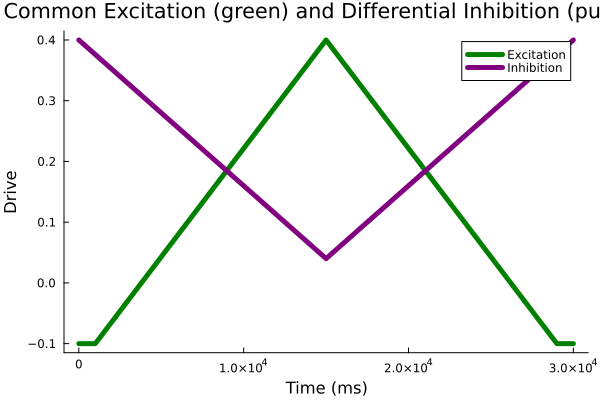

In [90]:
Plots.plot(tr, grid=false, linewidth=5, color=:green,label="Excitation", xlabel="Time (ms)", ylabel="Drive",title="Common Excitation (green) and Differential Inhibition (purple)",legend=:topright)
Plots.plot!(inh_input, grid=false, linewidth=5, color=:purple,label="Inhibition")

---

## 5. Run control algorithm

### 5.1 Controller configuration

In [91]:
# PD controller gains
kp = Float32(4.0)  # Proportional gain
kd = Float32(1.0)  # Derivative gain
dt = Float32(0.1)  # Time step

# Motoneurons to control
mn1 = 45  # Reference neuron
mn2 = 47  # Controlled neuron (receives differential inhibition)

# Initialize controller
previous_error = 0.0

# Define common excitatory input (will be updated by controller)
amplitude = 0.4
tr_length = 28000
half_triang = div(tr_length, 2)
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length=half_triang + 1)
down = range(amplitude, -0.1, length=tr_length - half_triang + 1)
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
tr_new = copy(tr)

max_diff = amplitude

println("Controller configuration:")
println("  Neurons: MN", mn1, " (reference) and MN", mn2, " (controlled)")
println("  Proportional gain (kp): ", kp)
println("  Derivative gain (kd): ", kd)
println("  Time step: ", dt, " ms")
println("  Max iterations: 20")

Controller configuration:
  Neurons: MN45 (reference) and MN47 (controlled)
  Proportional gain (kp): 4.0
  Derivative gain (kd): 1.0
  Time step: 0.1 ms
  Max iterations: 20


### 5.2 Execute control loop

**Control strategy:**
1. Update inhibition based on current excitation (inverse/constant/proportional)
2. Simulate both motoneurons
3. Compute 2D trajectory (MN1 vs MN2 firing rates)
4. **Phase 1**: Adjust excitation to follow diagonal trajectory (decorrelate)
5. **Phase 2**: Adjust excitation to follow vertical trajectory (increase MN2)

In [92]:
println("="^70)
println("STARTING CURSOR CONTROL")
println("="^70)
println()

for iteration in 1:20
    println("[Iteration ", iteration, " / 20]")
    
    # Update common input
    commoninput = tr_new
    
    # ================================================================
    # UPDATE INHIBITION BASED ON CURRENT EXCITATION
    # ================================================================
    
    # Inverse: inhibition inversely linked to excitation
    offset_correction = 0 - (-commoninput[15000])
    global inh_input[15000:end] = -commoninput[15000:end] .+ offset_correction
    
    # Balanced: (uncomment to use instead of inverse)
    # global inh_input[15000:end] = commoninput[15000:end] * 0.8
    
    # ================================================================
    # RUN SIMULATION FOR BOTH NEURONS
    # ================================================================
    
    global spike_arr_mn1, _ = run_sim_onemn(MN_list[mn1], mn1, inh_input)
    global spike_arr_mn2, _ = run_sim_onemn(MN_list[mn2], mn2, inh_input)
    
    # ================================================================
    # COMPUTE FIRING RATES (2D TRAJECTORY)
    # ================================================================
    
    # Convolve spikes to get smoothed firing rates
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)
    
    # Downsample for computational efficiency (average every 20 points)
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end
    
    global trajectory2_controlled = new_avg
    
    # ================================================================
    # DEFINE TARGET TRAJECTORIES
    # ================================================================
    
    # Diagonal trajectory: decorrelate (turn off MN1)
    start_x = 5; end_x = maximum(trajectory2_controlled[:, 1])
    start_y = 5; end_y = maximum(trajectory2_controlled[:, 2])
    x_values_diag = range(start_x, stop=Int(round(end_x)), 
                          length=Int(length(trajectory2_controlled[:, 1]) / 2))
    y_values_diag = range(start_y, stop=Int(round(end_y)), 
                          length=Int(length(trajectory2_controlled[:, 1]) / 2))
    trajectory1_diagonal = hcat(x_values_diag, y_values_diag)
    
    # Vertical trajectory: increase MN2 firing
    x_values = range(0.0, stop=maximum(trajectory2_controlled[:, 1]), 
                     length=length(trajectory2_controlled[:, 1]))
    y_values = ones(length(trajectory2_controlled[:, 2])) * maximum(trajectory2_controlled[:, 2])
    trajectory1_vertical = hcat(x_values, y_values)
    
    start = Int(size(trajectory1_vertical, 1) / 2)  # Start control halfway
    
    # ================================================================
    # PHASE 1: DIAGONAL TRAJECTORY CONTROL
    # ================================================================
    
    for i in start:(length(trajectory2_controlled[:, 1]) - 1)
        if i == start
            error1 = trajectory1_diagonal[i, 1] - trajectory2_controlled[i, 1]
            error2 = trajectory1_diagonal[i, 2] - trajectory2_controlled[i, 2]
            euclidean_error = sqrt(error1^2 + error2^2)
        else
            error1 = trajectory1_diagonal[start - (i - start) + 1, 1] - trajectory2_controlled[i, 1]
            error2 = trajectory1_diagonal[start - (i - start), 2] - trajectory2_controlled[i, 2]
            euclidean_error = sqrt(error1^2 + error2^2)
        end
        
        derivative_error = (euclidean_error - previous_error) / dt
        control_output = kp * euclidean_error + kd * derivative_error
        control_output *= 0.002  # Adaptive scaling
        
        tr_new[i] -= control_output
        
        if tr_new[i] < 0  # Clamp to valid range
            tr_new[i] = 0
        end
        
        global tr_new[15000] = 0.4  # Maintain peak
        previous_error = euclidean_error
    end
    
    # ================================================================
    # PHASE 2: VERTICAL TRAJECTORY CONTROL
    # ================================================================
    
    for i in start:length(trajectory2_controlled[:, 1])
        if round(trajectory2_controlled[i, 1]) < 5  # Only if MN1 firing is low
            error1 = trajectory1_vertical[i, 1] - trajectory2_controlled[i, 1]
            error2 = trajectory1_vertical[i, 2] - trajectory2_controlled[i, 2]
            euclidean_error = sqrt(error1^2 + error2^2)
            
            derivative_error = (euclidean_error - previous_error) / dt
            control_output = kp * euclidean_error + kd * derivative_error
            control_output *= 0.0007  # Adaptive scaling (different for vertical)
            
            tr_new[i] += control_output
            tr_new[15000] = amplitude
            
            if tr_new[i] > 0.4  # Clamp to valid range
                tr_new[i] = 0.4
            end
            
            previous_error = euclidean_error
            global tr_new[15000] = 0.4
        end
        
        global tr_new[15000] = 0.4
    end
end

println()
println("="^70)
println("CURSOR CONTROL COMPLETED")
println("="^70)
println("\n✓ All control iterations finished!")

STARTING CURSOR CONTROL

[Iteration 1 / 20]
[Iteration 2 / 20]
[Iteration 3 / 20]
[Iteration 4 / 20]
[Iteration 5 / 20]
[Iteration 6 / 20]
[Iteration 7 / 20]
[Iteration 8 / 20]
[Iteration 9 / 20]
[Iteration 10 / 20]
[Iteration 11 / 20]
[Iteration 12 / 20]
[Iteration 13 / 20]
[Iteration 14 / 20]
[Iteration 15 / 20]
[Iteration 16 / 20]
[Iteration 17 / 20]
[Iteration 18 / 20]
[Iteration 19 / 20]
[Iteration 20 / 20]

CURSOR CONTROL COMPLETED

✓ All control iterations finished!


---

## 6. Compute muscle force

### 6.1 Force from spike trains

In [34]:
#Obtain spikes of the whole pool
full_input = zeros((nr_s, sim_length))
@time spike_array, vs_array,pt_arr = run_sim();

494.053448 seconds (21.38 G allocations: 351.157 GiB, 12.42% gc time, 0.01% compilation time)


In [35]:
# Compute muscle force using twitch dynamics
T = 0.05
force = zeros(2, size(spike_arr_mn1, 2))

for idx in [1, 2]
    neuron_idx = idx == 1 ? mn1 : mn2
    spike_train = idx == 1 ? spike_arr_mn1 : spike_arr_mn2
    
    firings = spike_train[1, :] / 0.05
    
    # Second-order filter for twitch dynamics
    a = [1, -2 * exp(-T / tpeak_S[neuron_idx]), exp(-2 * T / tpeak_S[neuron_idx])]
    b = [0, Apeak_S[neuron_idx] * (T^2 / tpeak_S[neuron_idx]) * exp(1 - T / tpeak_S[neuron_idx])]
    force[idx, :] = filt(b, a, firings)
    
    # Apply tetanic limit
    force[idx, force[idx, :] .> tetanic_S[neuron_idx]] .= tetanic_S[neuron_idx]
end

println("✓ Force computed for both neurons")
println("  MN", mn1, " peak force: ", round(maximum(force[1, :]), digits=3))
println("  MN", mn2, " peak force: ", round(maximum(force[2, :]), digits=3))

✓ Force computed for both neurons
  MN45 peak force: 0.436
  MN47 peak force: 0.438


---

## 7. Visualization

### 7.1 2D Cursor trajectory and input profiles

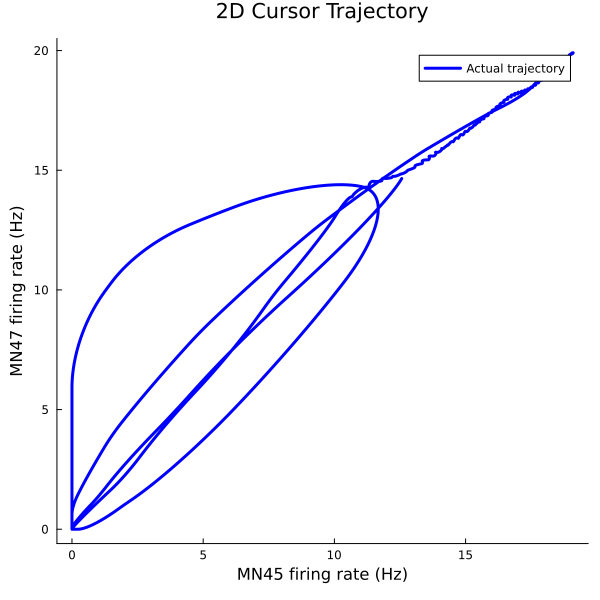

In [93]:
Plots.plot(trajectory2_controlled[:, 1], trajectory2_controlled[:, 2],xlabel="MN$(mn1) firing rate (Hz)",ylabel="MN$(mn2) firing rate (Hz)",title="2D Cursor Trajectory",linewidth=3, color=:blue, label="Actual trajectory",grid=false, legend=:topright, size=(600, 600))

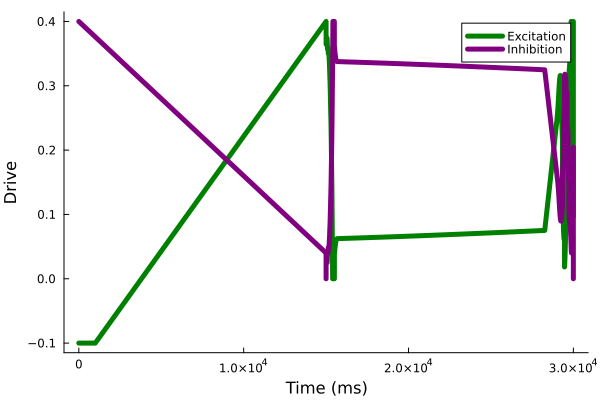

In [94]:
Plots.plot(tr_new, grid=false, linewidth=5, color=:green,label="Excitation", xlabel="Time (ms)", ylabel="Drive",legend=:topright)
Plots.plot!(inh_input, grid=false, linewidth=5, color=:purple,label="Inhibition")

### 7.2 Force output comparison

In [39]:
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);

T=0.05
twforce = zeros(size(spike_array))

for i in 1:size(spike_array, 1)
    firings = copy(spike_array) /0.05

    # filter coefficients
    a = [1, -2 * exp(-T / tpeak_S[i]), exp(-2 * T / tpeak_S[i])]
    b = [0, Apeak_S[i] * (T^2 / tpeak_S[i]) * exp(1 - T / tpeak_S[i])]

    twforce[i, :] = filt(b, a, firings[i, :])

    # Tetanic Limit
    twforce[i, twforce[i, :] .> tetanic_S[i]] .= tetanic_S[i]
end

force = sum(twforce, dims=1)# Sum forces from both neurons

Plots.plot(force[1,:], lw=5, color=:blue)

### 7.3 Force derivative (optional)

In [ ]:
# Uncomment to plot force derivative
# dt_force = 0.1
# force_derivative = diff(force[1, :]) ./ dt_force
# force_vals = force[1, :]
# der_vals = force_derivative
# Plots.plot(force_vals[1:599999], der_vals, width=5,
#     xlabel="Force", ylabel="dF/dt",
#     title="Force Derivative", grid=false)

---

## 8. Save results

### 8.1 Configure output paths

In [95]:
# Define output directory
# output_dir = "Data_MN_Model/Data_final/Controller_FINAL_results/S7"

output_dir = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/Test"


if !isdir(output_dir)
    mkpath(output_dir)
    println("Created output directory: ", output_dir)
end

# Determine control mode (change based on which inhibition strategy you used)
# control_mode = "pushpull"  # Options: "balanced", "pushpull", "constant"
control_mode = "pushpull_all"  # Options: "balanced", "pushpull", "constant"
exp_id = "TA_MN$(mn1)$(mn2)_$(control_mode)"

println("\nOutput configuration:")
println("  Experiment ID: ", exp_id)
println("  Directory: ", output_dir)


Output configuration:
  Experiment ID: TA_MN4547_pushpull_all
  Directory: /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller_FINAL_results/Test


### 8.2 Save data files

In [ ]:
# Save results based on control mode
# Uncomment the appropriate section:

# ========== BALANCED ==========
# control_mode = "balanced"
# exp_id = "TA_MN$(mn1)$(mn2)_$(control_mode)"
# JLD2.@save joinpath(output_dir, "trajectory_controlled_$(exp_id).jld2") trajectory2_controlled
# JLD2.@save joinpath(output_dir, "inh_$(exp_id).jld2") inh_input
# JLD2.@save joinpath(output_dir, "exc_$(exp_id).jld2") tr_new
# JLD2.@save joinpath(output_dir, "force_$(exp_id).jld2") force

# ========== PUSH-PULL (INVERSE) ==========
control_mode = "pushpull_noIF"
exp_id = "TA_MN$(mn1)$(mn2)_$(control_mode)"
JLD2.@save joinpath(output_dir, "trajectory_controlled_$(exp_id).jld2") trajectory2_controlled
JLD2.@save joinpath(output_dir, "inh_$(exp_id).jld2") inh_input
JLD2.@save joinpath(output_dir, "exc_$(exp_id).jld2") tr_new
# JLD2.@save joinpath(output_dir, "force_$(exp_id).jld2") force

# ========== CONSTANT ==========
# control_mode = "constant"
# exp_id = "TA_MN$(mn1)$(mn2)_$(control_mode)"
# JLD2.@save joinpath(output_dir, "trajectory_controlled_$(exp_id).jld2") trajectory2_controlled
# JLD2.@save joinpath(output_dir, "inh_$(exp_id).jld2") inh_input
# JLD2.@save joinpath(output_dir, "exc_$(exp_id).jld2") tr_new
# JLD2.@save joinpath(output_dir, "force_$(exp_id).jld2") force

println("\n✓ Ready to save results (uncomment appropriate section above)")


✓ Ready to save results (uncomment appropriate section above)


### 8.3 Load previously saved results (optional)

In [ ]:
# Uncomment to load previously saved results
# load_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Controller/TA_1314_changeinh_withstartPIC_2loop/"
# JLD2.@load joinpath(load_path, "force_TA_MN13_14_inh_PICstart.jld2") force
# JLD2.@load joinpath(load_path, "force_derivative.jld2") force_derivative
# println("✓ Results loaded from: ", load_path)

---

## 9. Alternative parameterisation: uniform VthCa and random IF

Sections 2.1 and 3.6 take one calcium threshold per motoneuron from the optimisation
(`VthCa_newTA`) and then derive the inhibition factor from it, so that `IF` is a
deterministic, inversely linear function of `VthCa`:

```julia
IF[i] = 1 - (VthCa[i] - min) / (max - min)
```

This section provides an alternative that breaks both assumptions: `VthCa` is made
uniform across motoneurons, and `IF` is drawn independently from a uniform distribution
on [0, 1] so that it no longer carries any relationship to `VthCa`.

**The zeros in `VthCa_newTA` are a mask, not a fitted value.** The optimisation assigns a
threshold only to the motoneurons that receive neuromodulation and leaves the rest at
exactly 0 — 67% of the pool for subject 1, 84% for subject 7. A median taken over the
whole pool therefore reports how many units were excluded rather than a typical
threshold, and comes out at 0 for every subject. Every summary below is taken over the
**neuromodulated subset only**, where the medians are 1.006 (subject 1) and 0.175
(subject 7).

That leaves a choice about who receives the uniform value, which `VTHCA_MODE` selects:

| mode | what it does |
|---|---|
| `:uniform_all` *(default)* | the summary value to **every** motoneuron, so the whole pool is neuromodulated at the same level |
| `:uniform_modulated` | the summary value only to the motoneurons the optimisation covered, zeros preserved elsewhere |
| `:zero_all` | 0 everywhere — no neuromodulation, as a floor condition |

`:uniform_all` is the default: every motoneuron receives the median of the optimised
values. Note that this changes two things at once relative to the optimised pool — the
spread of `VthCa` is removed *and* the neuromodulated fraction goes from 33% (subject 1)
or 16% (subject 7) to 100%. If you need to separate those, `:uniform_modulated` holds the
fraction fixed and changes only the spread; running both brackets the effect.

Note also that `VthCa` enters the model as an *offset* from spike threshold — the
prolongation conditions in `creation_model.jl` test `vs > Vth - VthCa` — so a motoneuron
at 0 has no PIC-mediated firing prolongation.

Nothing above this point is modified. Section 9.2 rebuilds `MNs` in place; to simulate
with it, re-run the control loop from section 5 onward. Section 9.3 restores the
original parameterisation the same way.

### 9.1 Build the alternative parameter sets

In [ ]:
using Statistics, Random, Printf

# --- which motoneurons get the uniform VthCa (see the table above) -----------
VTHCA_MODE = :uniform_all         # :uniform_all | :uniform_modulated | :zero_all
VTHCA_STAT = :median              # over the OPTIMISED values only: :median | :mean

# --- how IF is drawn ---------------------------------------------------------
IF_MODE = :random_all             # :random_all | :random_modulated
IF_SEED = 1234                    # change for a different random assignment

# Keep the originals so section 9.3 can restore them.
vthca_original = vec(Vthca_S)
IF_original    = copy(IF)

vthca_all = vec(VthCa_newTA)
modulated = findall(!=(0.0), vthca_all)   # motoneurons the optimisation covered
isempty(modulated) && error("no non-zero VthCa values found")

vthca_value = VTHCA_STAT === :median ? median(vthca_all[modulated]) :
              VTHCA_STAT === :mean   ? mean(vthca_all[modulated])   :
              error("VTHCA_STAT must be :median or :mean")

vthca_uniform = if VTHCA_MODE === :uniform_modulated
    v = zeros(nr_s); v[modulated] .= vthca_value; v
elseif VTHCA_MODE === :uniform_all
    fill(vthca_value, nr_s)
elseif VTHCA_MODE === :zero_all
    zeros(nr_s)
else
    error("VTHCA_MODE must be :uniform_modulated, :uniform_all or :zero_all")
end

rng = MersenneTwister(IF_SEED)
IF_random = if IF_MODE === :random_all
    rand(rng, nr_s)
elseif IF_MODE === :random_modulated
    v = copy(IF_original); v[modulated] .= rand(rng, length(modulated)); v
else
    error("IF_MODE must be :random_all or :random_modulated")
end

@printf("Pool: %d motoneurons, %d neuromodulated (%.0f%%), %d left at zero\n\n",
        nr_s, length(modulated), 100length(modulated)/nr_s, nr_s - length(modulated))

println("VthCa over the neuromodulated subset")
@printf("  range  %.4f .. %.4f     median %.4f     mean %.4f\n",
        minimum(vthca_all[modulated]), maximum(vthca_all[modulated]),
        median(vthca_all[modulated]), mean(vthca_all[modulated]))
@printf("  (median over the whole pool is %.4f -- dominated by the excluded units)\n",
        median(vthca_all))

@printf("\nVTHCA_MODE = %s, VTHCA_STAT = %s  ->  uniform value %.4f\n",
        VTHCA_MODE, VTHCA_STAT, vthca_value)
@printf("  motoneurons receiving it : %d of %d\n",
        count(!=(0.0), vthca_uniform), nr_s)

@printf("\nIF_MODE = %s (seed %d)\n", IF_MODE, IF_SEED)
@printf("  original : %.4f .. %.4f   median %.4f   sd %.4f\n",
        minimum(IF_original), maximum(IF_original), median(IF_original), std(IF_original))
@printf("  new      : %.4f .. %.4f   median %.4f   sd %.4f\n",
        minimum(IF_random), maximum(IF_random), median(IF_random), std(IF_random))

@printf("\ncorrelation IF vs VthCa (neuromodulated subset only)\n")
@printf("  original %+.3f   new %+.3f\n",
        cor(IF_original[modulated], vthca_original[modulated]),
        cor(IF_random[modulated], vthca_original[modulated]))

### 9.1.1 Distributions

Left column: value per motoneuron across the pool. Middle: the distribution of those
values. Right: `IF` plotted against `VthCa`, which shows the relationship the original
parameterisation imposes and its absence in the alternative.

In [ ]:
# Plots is used throughout this notebook; prefix explicitly since Makie is also loaded.
notmod = setdiff(1:nr_s, modulated)

p1 = Plots.scatter(modulated, vthca_original[modulated], ms=4, color=:steelblue,
                   markerstrokewidth=0, label="optimised (neuromodulated)",
                   xlabel="Motoneuron index", ylabel="VthCa",
                   title="VthCa per motoneuron", grid=false)
Plots.scatter!(p1, notmod, vthca_original[notmod], ms=2, color=:grey70,
               markerstrokewidth=0, label="not neuromodulated (0)")
Plots.plot!(p1, 1:nr_s, vthca_uniform, lw=2, color=:darkorange,
            label="uniform ($(VTHCA_MODE))")

p2 = Plots.histogram(vthca_original[modulated], bins=20, color=:steelblue, alpha=0.65,
                     label="optimised (neuromodulated)", xlabel="VthCa", ylabel="Count",
                     title="VthCa, neuromodulated subset", grid=false)
Plots.vline!(p2, [vthca_value], lw=3, color=:darkorange,
             label="uniform value ($(VTHCA_STAT))")

p3 = Plots.scatter(vthca_original[modulated], IF_original[modulated], ms=4,
                   color=:steelblue, markerstrokewidth=0, label="original",
                   xlabel="VthCa", ylabel="IF", title="IF vs VthCa (original)",
                   grid=false, ylims=(0, 1))

p4 = Plots.scatter(1:nr_s, IF_original, ms=3, color=:steelblue, markerstrokewidth=0,
                   label="from VthCa", xlabel="Motoneuron index", ylabel="IF",
                   title="IF per motoneuron", grid=false, ylims=(0, 1))
Plots.scatter!(p4, 1:nr_s, IF_random, ms=3, color=:darkorange, markerstrokewidth=0,
               label="new ($(IF_MODE))")

p5 = Plots.histogram(IF_original, bins=20, color=:steelblue, alpha=0.65,
                     label="from VthCa", xlabel="IF", ylabel="Count",
                     title="IF distribution", grid=false)
Plots.histogram!(p5, IF_random, bins=20, color=:darkorange, alpha=0.65,
                 label="new ($(IF_MODE))")

p6 = Plots.scatter(vthca_uniform[modulated], IF_random[modulated], ms=4,
                   color=:darkorange, markerstrokewidth=0, label="alternative",
                   xlabel="VthCa", ylabel="IF", title="IF vs VthCa (alternative)",
                   grid=false, ylims=(0, 1))

Plots.plot(p1, p2, p3, p4, p5, p6, layout=(2, 3), size=(1400, 720),
           legend=:best, titlefontsize=10, legendfontsize=7,
           left_margin=5 * Plots.mm, bottom_margin=5 * Plots.mm)

### 9.2 Rebuild the pool with the alternative parameters

`rebuild_MNs` reassembles `MNs` from the per-motoneuron properties already computed in
section 3.8, substituting the supplied `VthCa` and `IF`. Every other property —
conductances, capacitances, rheobase, spike threshold, twitch parameters — is reused
unchanged, so the only difference from the pool built in 3.8 is the two vectors passed
in here.

After running this cell, re-run section 5 onward to simulate with the new pool.

In [ ]:
function rebuild_MNs(vthca_vec, if_vec)
    length(vthca_vec) == nr_s || error("VthCa vector must have $nr_s entries")
    length(if_vec)    == nr_s || error("IF vector must have $nr_s entries")

    pool = []
    for i in 1:nr_s
        S_MN = Dict(
            :Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i],
            :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i],
            :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i],
            :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i],
            :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i],
            :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i],
            :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i],
            :VthCa => vthca_vec[i], :Rn => rn_S[i],
            :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],
            :IF => if_vec[i], :tpeak => tpeak_S[i], :γh => γh[i],
            "type" => "All Type"
        )
        pool = [pool; S_MN]
    end
    return pool
end

# Apply the alternative parameterisation.
Vthca_S = vthca_uniform
IF      = IF_random
MNs     = rebuild_MNs(vthca_uniform, IF_random)

@printf("Pool rebuilt: %d motoneurons\n", length(MNs))
@printf("  VthCa in MNs : %.4f .. %.4f\n",
        minimum(m[:VthCa] for m in MNs), maximum(m[:VthCa] for m in MNs))
@printf("  IF in MNs    : %.4f .. %.4f\n",
        minimum(m[:IF] for m in MNs), maximum(m[:IF] for m in MNs))
if (@isdefined mn1) && (@isdefined mn2)
    @printf("\n  controlled neurons now: MN%d VthCa=%.4f IF=%.4f | MN%d VthCa=%.4f IF=%.4f\n",
            mn1, MNs[mn1][:VthCa], MNs[mn1][:IF], mn2, MNs[mn2][:VthCa], MNs[mn2][:IF])
end

println("\nNext: re-run section 5.1 (resets tr_new and previous_error), then 5.2.")
println("Skipping 5.1 restarts the controller from its converged input and the")
println("output will look unchanged regardless of the pool.")

### 9.3 Restore the original parameterisation (optional)

**This cell is commented out on purpose.** It undoes 9.2, so if it ran as part of a
straight top-to-bottom pass through section 9 it would put the optimised pool back and
section 5 would behave exactly as before — the alternative would never be simulated.

Uncomment and run it only when you want to go back to the optimised `VthCa` and the
`VthCa`-derived `IF`, without re-running sections 2 and 3.

In [ ]:
# Uncomment to restore the optimised VthCa and the VthCa-derived IF.

# Vthca_S = vthca_original
# IF      = IF_original
# MNs     = rebuild_MNs(vthca_original, IF_original)
#
# @printf("Pool restored: %d motoneurons\n", length(MNs))
# @printf("  VthCa in MNs : %.4f .. %.4f\n",
#         minimum(m[:VthCa] for m in MNs), maximum(m[:VthCa] for m in MNs))
# @printf("  IF in MNs    : %.4f .. %.4f\n",
#         minimum(m[:IF] for m in MNs), maximum(m[:IF] for m in MNs))
# println("\nRe-run section 5 onward to simulate with the original pool.")